# A tour of pylovo

pylovo builds synthetic low-voltage (LV) grids for whole regions from open data: building footprints, streets and
census figures. For every postcode area it places the MV/LV stations, routes and sizes the cables and checks each
grid with a power flow. This tour shows the result for one postcode area in three figures.

**Needs:** the `notebooks` extra (`uv sync --extra notebooks`). With a database in your `.env` the notebook reads the grids from it, otherwise from the example data that ship with pylovo (`data/examples`: three Bavarian postcode areas).

In [1]:
plz = 85256          # 80805 München (urban), 85256 Vierkirchen (semi-urban), 85307 Paunzhausen (rural)
version_id = None    # None: the version of your configuration, or of the example data

In [2]:
import pandas as pd

from pylovo.examples import TutorialData
from pylovo.plotting import lv_grid, style

style.apply_style(dpi=150)
data = TutorialData(plz, version_id)
data

TutorialData(plz=85256, version 1, from the example data: no database configured)

## 1 All LV grids of the area

Each colour is one LV grid, each star the MV/LV station that supplies it.

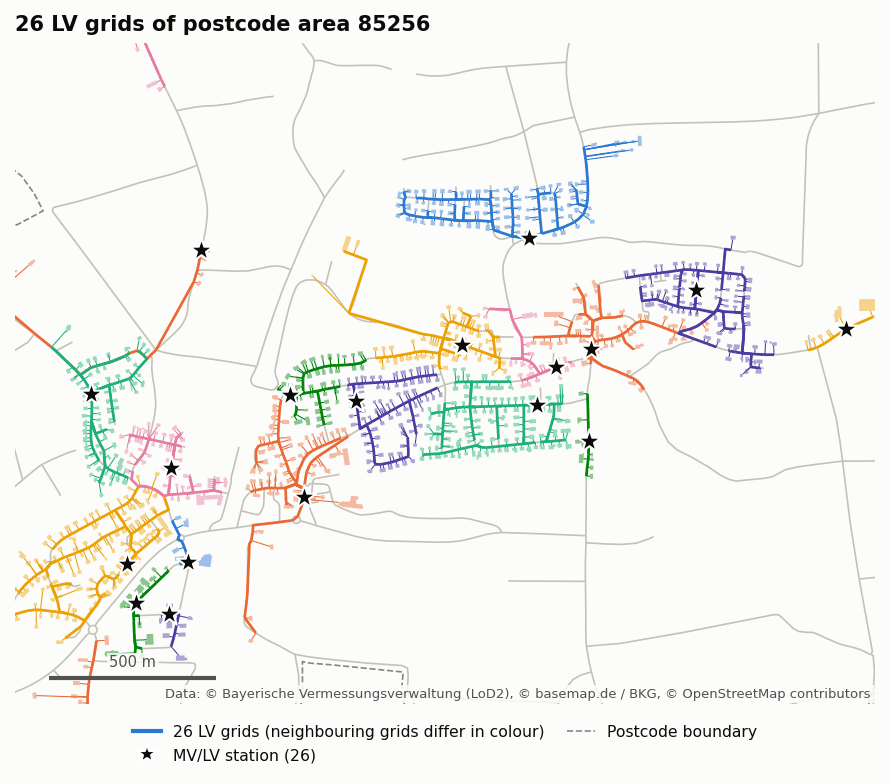

In [3]:
fig = lv_grid.plot_lv_overview(data.layers, extent="core")

The cables follow the streets to the houses, and each grid serves the buildings around its station. Neighbouring
grids differ in colour; the colours carry no other meaning. In numbers:

In [4]:
summary = data.summary()
pd.Series({
    "LV grids": len(summary),
    "buildings supplied": summary["buildings"].sum(),
    "households": summary["households"].sum(),
    "transformer power (kVA)": summary["transformer_rated_power"].sum(),
    "feeder cables (km)": round(summary["feeder_km"].sum(), 1),
    "house connections (km)": round(summary["service_km"].sum(), 1),
}, dtype=object).to_frame(f"postcode area {plz}")

,postcode area 85256
LV grids,26
buildings supplied,1333
households,2051
transformer power (kVA),12470
feeder cables (km),31.8
house connections (km),21.5


## 2 One grid up close

A typical grid of the area, with its cables coloured by type and its buildings by their peak load.

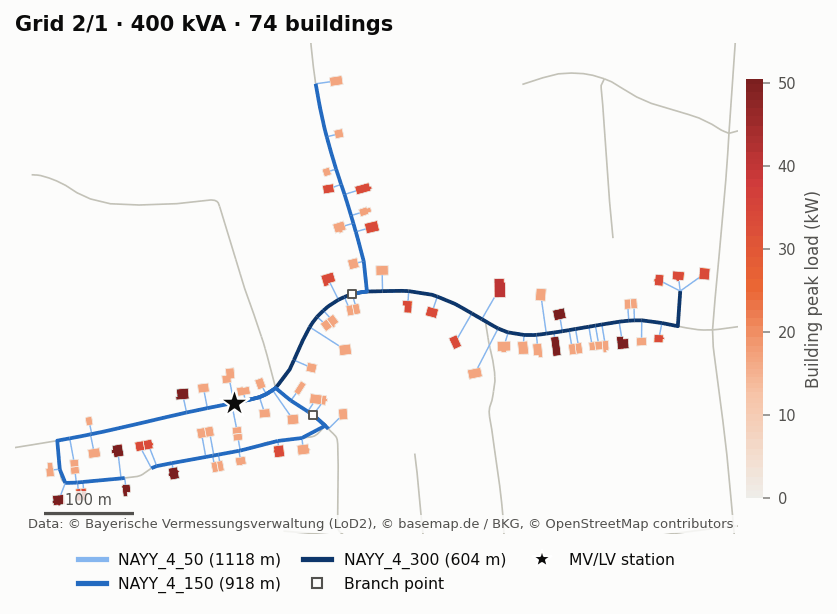

In [5]:
kcid, bcid = data.typical_grid
fig = lv_grid.plot_lv_grid(data.layers, kcid, bcid)

- Thick lines are the feeders, thin lines the house connections. The feeder cables are dimensioned for the load
  they carry and for the voltage drop at their end.
- Each grid is identified by two numbers: `kcid`, its k-means cluster of the postcode area, and `bcid`, the
  building cluster that one station supplies.

## 3 Does the grid hold its voltage?

pylovo checks every grid with a power flow at peak load. The profile shows the voltage along each feeder over the
cable distance from the station.

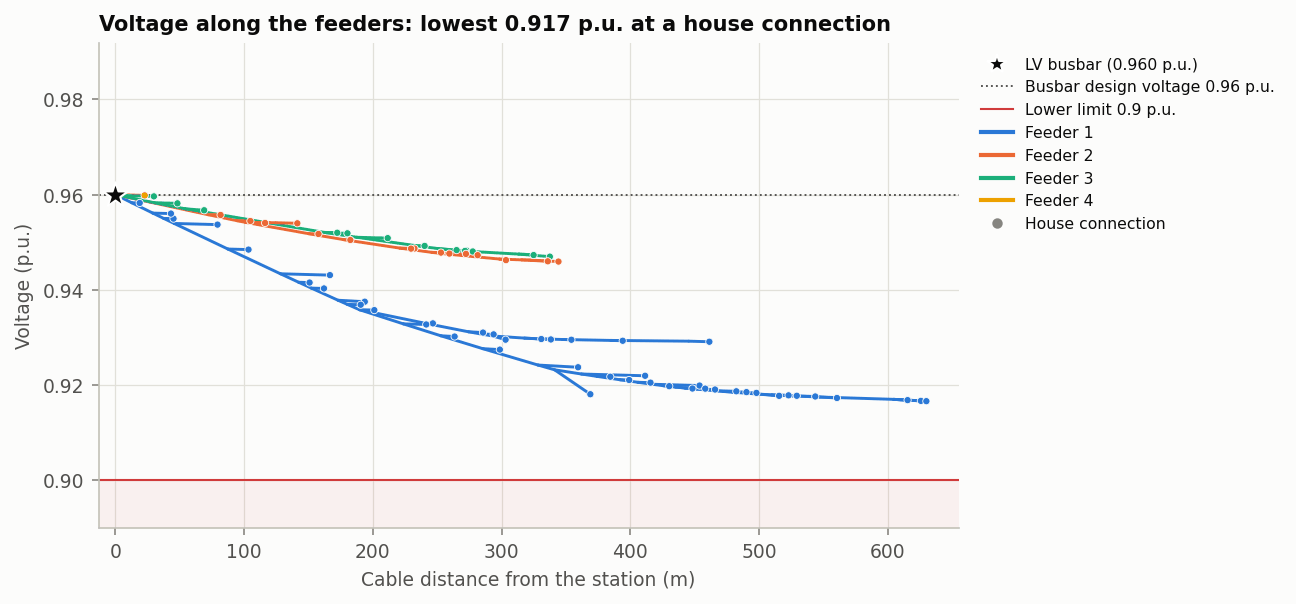

In [6]:
net = data.net(kcid, bcid)
fig = lv_grid.plot_feeder_voltage_profile(net, data.voltage_band)

- The busbar of the station starts at the design voltage of the version. The MV grid and the transformer use the
  rest of the voltage band.
- The voltage falls along every feeder. The lowest house connection must stay above the lower limit.
- `net` is an ordinary pandapower net: `pandapower.runpp(net)` runs the power flow again, `net.line` and
  `net.res_bus` hold the cables and the results.

## Where to go next

| Notebook | Question |
| --- | --- |
| `02_building_grids` | How does pylovo build the grids, step by step? |
| `03_one_grid` | What is inside one grid, and how does it behave? |
| `04_comparing_areas` | How do the grids of a city, a suburb and a village differ? |
| `05_versions` | How much do the generation settings change the grids? |
| `06_voltage_levels` | How is an LV grid connected to the MV and the HV grid? |
| `classification/01`, `classification/02` | Which types of grids are there in Bavaria? |

Change `plz` in the parameter cell and run the notebook again to see another area. With a database, the map viewer
(`uv run pylovo-viewer`) shows all grids interactively.